In [1]:
from pathlib import Path

from torchvision.datasets import MNIST

# CNN.ipynb가 있는 디렉터리를 커널의 작업 디렉터리로 사용
data_dir = Path.cwd().parent / "data"

train_data = MNIST(
    root=str(data_dir),
    train=True,
    download=True,
)
test_data = MNIST(
    root=str(data_dir),
    train=False,
    download=True,
)

In [2]:
import torch
from torch import nn
from IPython.display import display

class CNN(nn.Module):
    def __init__(self) -> None:
        super().__init__()
        self.features: nn.Sequential = nn.Sequential(
            #(28*28*1)의 이미지를 (28*28*8)로 변환, padding=1로 이미지 크기 유지
            nn.Conv2d(1, 14, kernel_size=3, padding=1),
            nn.ReLU(),
            
            nn.Conv2d(14, 10, kernel_size=3, padding=1),
            nn.ReLU(),
            
            nn.Conv2d(10, 8, kernel_size=3, padding=1),
            nn.ReLU(),

            #(14*14*8)의 이미지를 (14*14*16)로 변환, padding=1로 이미지 크기 유지
            nn.Conv2d(8, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),
        )
        self.classifier: nn.Sequential = nn.Sequential(
            #2차원 이미지를 1차원으로 flatten, 클래스 분류를 위해...
            nn.Flatten(start_dim=1),
            # Conv layers preserve 28x28; one MaxPool reduces it to 14x14.
            nn.Linear(16 * 14 * 14, 64),
            nn.ReLU(),
            nn.Linear(64, 10),
        )

    def forward(self, images: torch.Tensor) -> torch.Tensor:
        """[배치, 1, 28, 28] 입력을 [배치, 10] logits로 변환합니다."""
        return self.classifier(self.features(images))
    
    
model = CNN()
display(model) 
    

CNN(
  (features): Sequential(
    (0): Conv2d(1, 14, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(14, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU()
    (4): Conv2d(10, 8, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): ReLU()
    (6): Conv2d(8, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=3136, out_features=64, bias=True)
    (2): ReLU()
    (3): Linear(in_features=64, out_features=10, bias=True)
  )
)

In [3]:
parameter_count = sum(
    parameter.numel() for parameter in model.parameters() if parameter.requires_grad
)
display(f"학습 가능한 파라미터 수: {parameter_count:,}")

'학습 가능한 파라미터 수: 204,724'

학습: 800장 | 검증: 100장


'학습 장치: cuda'

'Epoch 1/30 | train loss: 2.2208, accuracy: 17.88% | test loss: 1.4909, accuracy: 49.00%'

'Epoch 10/30 | train loss: 0.0448, accuracy: 98.75% | test loss: 0.2678, accuracy: 95.00%'

'Epoch 20/30 | train loss: 0.0309, accuracy: 99.00% | test loss: 0.2505, accuracy: 93.00%'

'Epoch 30/30 | train loss: 0.0085, accuracy: 99.75% | test loss: 0.2413, accuracy: 92.00%'

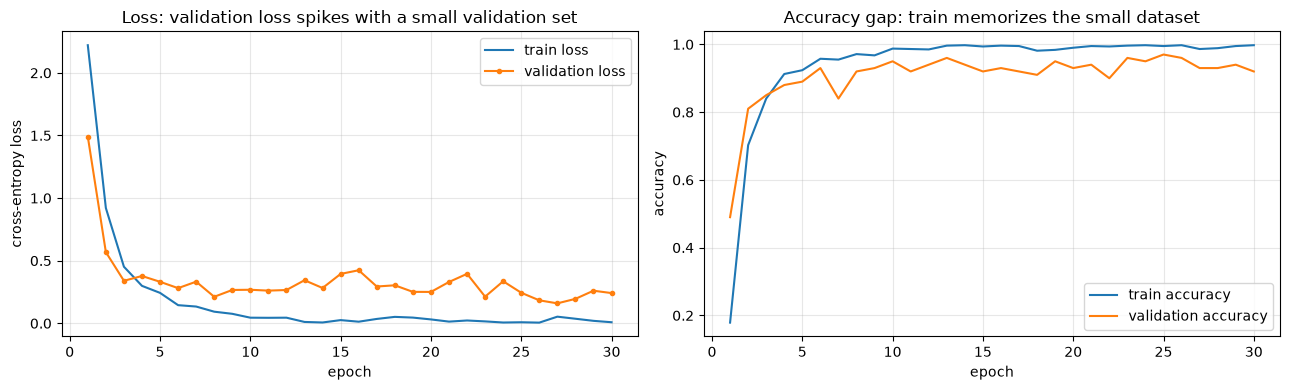

In [ ]:
from pathlib import Path

import torch
from IPython.display import display
from torch import nn
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader, Subset
from torchvision.datasets import MNIST
from torchvision.transforms import ToTensor

EPOCHS = 30
BATCH_SIZE = 32
LEARNING_RATE = 0.01
SEED = 42
TRAIN_SAMPLES = 800
VAL_SAMPLES = 100  # train:validation = 8:1

torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = CNN().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)

# PIL 이미지를 [1, 28, 28] 텐서로 변환합니다.
# 현재 작업 폴더가 프로젝트 루트/3.ResNet 어느 쪽이어도 data 폴더를 찾습니다.
project_root = Path.cwd().resolve()
if not (project_root / "data").exists() and (project_root.parent / "data").exists():
    project_root = project_root.parent

transform = ToTensor()
full_train_set = MNIST(project_root / "data", train=True, download=True, transform=transform)
full_val_set = MNIST(project_root / "data", train=False, download=True, transform=transform)

# 무작위로 고른 800장만 학습하고, 검증 데이터는 100장으로 8:1 비율을 맞춥니다.
indices = torch.randperm(len(full_train_set), generator=torch.Generator().manual_seed(SEED))
train_set = Subset(full_train_set, indices[:TRAIN_SAMPLES].tolist())
test_set = Subset(full_val_set, list(range(VAL_SAMPLES)))
print(f"학습: {len(train_set):,}장 | 검증: {len(test_set):,}장")

train_loader = DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True)
test_loader = DataLoader(test_set, batch_size=BATCH_SIZE)

display(f"학습 장치: {device}")
history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
for epoch in range(1, EPOCHS + 1):
    # 학습: 순전파 → 손실 계산 → 역전파 → 가중치 갱신
    model.train()
    train_loss, train_correct = 0.0, 0
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad(set_to_none=True)
        logits = model(images)
        loss = criterion(logits, labels)
        loss.backward()
        optimizer.step()
        train_loss += loss.item() * labels.size(0)
        train_correct += (logits.argmax(dim=1) == labels).sum().item()

    # 평가: 가중치를 갱신하지 않고 테스트 데이터로 확인합니다.
    model.eval()
    test_loss, test_correct = 0.0, 0
    with torch.inference_mode():
        for images, labels in test_loader:
            images, labels = images.to(device), labels.to(device)
            logits = model(images)
            test_loss += criterion(logits, labels).item() * labels.size(0)
            test_correct += (logits.argmax(dim=1) == labels).sum().item()

    history["train_loss"].append(train_loss / len(train_set))
    history["val_loss"].append(test_loss / len(test_set))
    history["train_acc"].append(train_correct / len(train_set))
    history["val_acc"].append(test_correct / len(test_set))

    if epoch == 1 or epoch % 10 == 0:
        display(
            f"Epoch {epoch}/{EPOCHS} | "
            f"train loss: {train_loss / len(train_set):.4f}, "
            f"accuracy: {train_correct / len(train_set):.2%} | "
            f"test loss: {test_loss / len(test_set):.4f}, "
            f"accuracy: {test_correct / len(test_set):.2%}"
        )

epochs = range(1, EPOCHS + 1)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(epochs, history["train_loss"], label="train loss")
axes[0].plot(epochs, history["val_loss"], marker="o", markersize=3, label="validation loss")
axes[0].set_title("Loss: validation loss spikes with a small validation set")
axes[0].set_xlabel("epoch")
axes[0].set_ylabel("cross-entropy loss")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(epochs, history["train_acc"], label="train accuracy")
axes[1].plot(epochs, history["val_acc"], label="validation accuracy")
axes[1].set_title("Accuracy gap: train memorizes the small dataset")
axes[1].set_xlabel("epoch")
axes[1].set_ylabel("accuracy")
axes[1].legend()
axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [5]:
from pathlib import Path

import torch
from IPython.display import display
from PIL import Image
from torchvision.datasets import MNIST
from torchvision.transforms import ToTensor

INPUT_SIZE = (28, 28)
PREVIEW_SIZE = (280, 280)
inference_data = MNIST(Path.cwd().parent / "data", train=False, download=False)
transform = ToTensor()


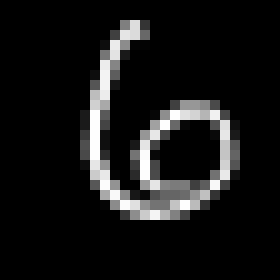

'정답: 6 | 예측: 6 | 예측 확률: 100.00% | 결과: 정답'

In [6]:
sample_index = 100
if not 0 <= sample_index < len(inference_data):
    raise IndexError(f"sample_index는 0 이상 {len(inference_data)} 미만이어야 합니다.")

sample_image, target_label = inference_data[sample_index]
prepared_image = sample_image.convert("L").resize(INPUT_SIZE, Image.Resampling.BILINEAR)
inputs = transform(prepared_image).unsqueeze(0).to(next(model.parameters()).device)

model.eval()
with torch.inference_mode():
    probabilities = model(inputs).softmax(dim=1)
    confidence, prediction = probabilities.max(dim=1)

predicted_label = prediction.item()
display(sample_image.resize(PREVIEW_SIZE, Image.Resampling.NEAREST))
display(
    f"정답: {target_label} | 예측: {predicted_label} | "
    f"예측 확률: {confidence.item():.2%} | "
    f"결과: {'정답' if predicted_label == target_label else '오답'}"
)


'테스트 샘플: 100 | 정답: 6 | 원본 예측: 6 | 원본 예측 확률: 100.00%'

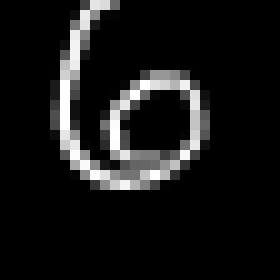

'좌상 (x=-3, y=-3 px) | 정답: 6 | 예측: 9 | 예측 확률: 77.19% | 결과: 오답'

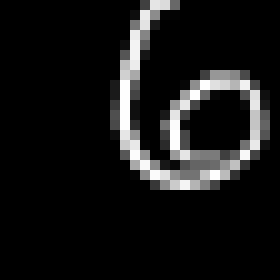

'우상 (x=+3, y=-3 px) | 정답: 6 | 예측: 4 | 예측 확률: 59.47% | 결과: 오답'

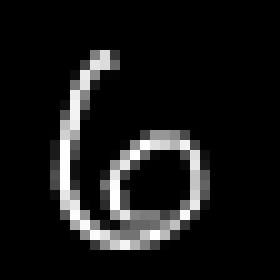

'좌하 (x=-3, y=+3 px) | 정답: 6 | 예측: 0 | 예측 확률: 99.04% | 결과: 오답'

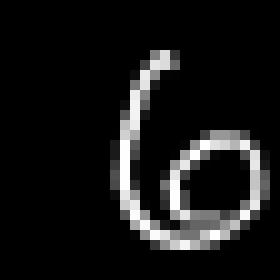

'우하 (x=+3, y=+3 px) | 정답: 6 | 예측: 8 | 예측 확률: 99.80% | 결과: 오답'

In [7]:
# 7번 셀에서 선택한 동일한 이미지를 네 대각선 방향으로 이동합니다.
shift_pixels = 3
source_image, target_label = inference_data[sample_index]
source_image = source_image.convert("L").resize(INPUT_SIZE, Image.Resampling.BILINEAR)
directions = (
    ("좌상", -shift_pixels, -shift_pixels),
    ("우상", shift_pixels, -shift_pixels),
    ("좌하", -shift_pixels, shift_pixels),
    ("우하", shift_pixels, shift_pixels),
)

shifted_images: list[Image.Image] = []
for direction, dx, dy in directions:
    shifted_image = Image.new("L", INPUT_SIZE, color=0)
    shifted_image.paste(source_image, (dx, dy))
    shifted_images.append(shifted_image)

# 원본과 이동 이미지 네 장을 한 배치로 추론합니다.
comparison_images = [source_image, *shifted_images]
shift_inputs = torch.stack([transform(image) for image in comparison_images])
shift_inputs = shift_inputs.to(next(model.parameters()).device)
model.eval()
with torch.inference_mode():
    shift_probabilities = model(shift_inputs).softmax(dim=1)
    shift_confidences, shift_predictions = shift_probabilities.max(dim=1)

# 원본을 기준으로 이동 방향별 예측 변화와 확률을 확인합니다.
display(
    f"테스트 샘플: {sample_index} | 정답: {target_label} | "
    f"원본 예측: {shift_predictions[0].item()} | "
    f"원본 예측 확률: {shift_confidences[0].item():.2%}"
)
for index, (direction, dx, dy) in enumerate(directions, start=1):
    label = shift_predictions[index].item()
    display(shifted_images[index - 1].resize(PREVIEW_SIZE, Image.Resampling.NEAREST))
    display(
        f"{direction} (x={dx:+d}, y={dy:+d} px) | "
        f"정답: {target_label} | 예측: {label} | "
        f"예측 확률: {shift_confidences[index].item():.2%} | "
        f"결과: {'정답' if label == target_label else '오답'}"
    )
